# Walkthrough of the partition-closed core model

This notebook reads the sourced ledgers, recomputes the published best-fit composition from the
equation of state up, reruns the baseline composition search, and summarizes the sensitivity
scenarios and the Monte Carlo stored in `production/`. It takes about a minute and writes nothing.

The full pipeline, including the 400-draw Monte Carlo and every figure, is `bash reproduce.sh`.
Run this notebook from the `core/` directory in the `earthcore-engine` environment
(`conda env create -f ../environment.yml`).

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
import full_space_rerun as F

eos = json.load(open("eos_params.json"))
pp = json.load(open("partition_params.json"))
best = json.load(open("production/best_fit.json"))
caps = best["caps_wt_pct"]

## 1. The equation-of-state ledger

Each solid endmember is a Mie-Grueneisen-Debye mineral evaluated with BurnMan. Every parameter
carries its source in `eos_params.json`; the sulfide sits in `partition_params.json` because it
enters at the partitioning stage.

In [2]:
ems = dict(eos["endmembers"])
ems["Fe3S"] = pp["solid_sulfide_endmember"]["Fe3S"]
pd.DataFrame([{
    "phase": name,
    "V0 (cm3/mol)": e["V_0"]["value"],
    "K0 (GPa)": e["K_0"]["value"],
    "K'": e["Kprime_0"]["value"],
    "gamma0": e["grueneisen_0"]["value"],
    "q": e["q_0"]["value"],
    "theta0 (K)": e["Debye_0"]["value"],
    "K0 source": e["K_0"]["source"],
} for name, e in ems.items()]).set_index("phase")

,V0 (cm3/mol),K0 (GPa),K',gamma0,q,theta0 (K),K0 source
phase,,,,,,,
hcp_Fe,6.753,163.4,5.38,1.875,1.305,417.0,"Dewaele 2006, Table III"
B2_FeSi,12.828,230.6,4.17,1.300,1.700,417.0,"Fischer 2014, Table 1"
B8_FeO,11.997,137.8,4.00,1.730,1.000,417.0,"Fischer 2011 EPSL, B8"
B1_FeO,12.256,149.4,3.60,1.410,0.500,417.0,"Fischer 2011 EPSL, B1"
Fe7C3,53.000,291.0,4.50,2.570,2.200,920.0,Mookherjee/Nakajima 2011
Fe3S,28.380,156.0,3.80,1.010,1.000,417.0,Seagle et al. 2006 (BM3)


## 2. Partition coefficients

The inner core crystallizes from the outer core, so each element's solid content is its liquid
content times D = x(solid)/x(liquid). Carbon's coefficient is the contested one: above 1 if carbon
enters the inner core, about 6e-5 in the first-principles work of Li et al. (2019).

In [3]:
pd.DataFrame([{"element": el, "D": v["D"], "source": v["source"]}
              for el, v in pp["partition_coefficients"].items() if not el.startswith("_")]).set_index("element")

,D,source
element,,
O,0.02,Alfe et al. 2000 Nature 405 172; 2002 EPSL 195 91
S,0.75,Alfe et al. 2002 EPSL 195 91; corroborated by ...
Si,0.80,Alfe 2002 EPSL 195 91; Badro 2014; also Sakai ...
C,1.50,Chen et al. 2014 PNAS 111 17755; Prescher et a...
Ni,1.00,assumption; Fe-Ni context Wei et al. 2025 Sci....


## 3. The published best fit, recomputed

The stored best-fit outer-core liquid is evaluated again from the ledgers. Its liquid density and
bulk sound speed are compared with PREM at the core-mantle boundary (CMB) and at the inner-core
boundary (ICB); the partitioned solid is compared with PREM's inner core at 5800 K. The six
misfits must match `best_fit.json`, and each must sit inside its tolerance for the composition
to count as admissible.

In [4]:
F._init(None, "equal_to_O", False, caps)
M = F._M
pr_cmb, pr_icb = M.prem_outer(M.P_CMB), M.prem_outer(M.P_ICB)
x = best["liquid_x"]
fit = F._eval(x["C"], x["O"], x["Si"], x["S"], 5800, pr_cmb, pr_icb)

labels = {"lc_rho": "liquid density, CMB", "lc_v": "liquid sound speed, CMB",
          "li_rho": "liquid density, ICB", "li_v": "liquid sound speed, ICB",
          "s_rho": "solid density, inner core", "s_v": "solid sound speed, inner core"}
check = pd.DataFrame({"misfit recomputed (%)": {labels[k]: fit[k] for k in F.TOL},
                      "misfit stored (%)": {labels[k]: best["misfit_pct"][k] for k in F.TOL},
                      "tolerance (%)": {labels[k]: F.TOL[k] for k in F.TOL}})
assert np.allclose(check.iloc[:, 0], check.iloc[:, 1], rtol=0, atol=1e-9)
assert np.isclose(fit["rms_misfit_pct"], best["rms_misfit_pct"], rtol=0, atol=1e-9)
print(f"rms misfit {fit['rms_misfit_pct']:.2f} %, ICB density jump {fit['icb_jump_pct']:.1f} %")
check.round(3)

rms misfit 0.94 %, ICB density jump 7.2 %


,misfit recomputed (%),misfit stored (%),tolerance (%)
"liquid density, CMB",0.211,0.211,1.0
"liquid density, ICB",-0.952,-0.952,1.0
"liquid sound speed, CMB",-1.060,-1.060,2.0
"liquid sound speed, ICB",1.047,1.047,2.0
"solid density, inner core",1.229,1.229,1.5
"solid sound speed, inner core",-0.807,-0.807,2.5


In [5]:
pd.DataFrame({"outer core (wt%)": best["liquid_wt_pct"],
              "inner core (wt%)": best["solid_wt_pct"]}).round(2)

,outer core (wt%),inner core (wt%)
O,2.59,0.05
Si,2.28,1.73
S,1.62,1.16
C,0.97,1.39


## 4. The baseline search, rerun

The production search covers oxygen, silicon, sulfur and carbon in the liquid, with carbon,
silicon and sulfur held to the published limits in `best_fit.json`. The grid below is the one
`full_space_rerun.py --production` builds; the asserts confirm it tests the same compositions
and finds the same admissible set and best fit.

In [6]:
top = {"C": caps["C"] * 4.6 / 100, "Si": caps["Si"] * 1.95 / 100, "S": caps["S"] * 1.75 / 100}
grid = dict(O=np.round(np.arange(0, 0.205, 0.01), 3),
            Si=np.round(np.arange(0, min(top["Si"], 0.10) + 1e-9, 0.01), 3),
            S=np.round(np.arange(0, min(top["S"], 0.06) + 1e-9, 0.005), 4),
            C=np.round(np.arange(0, min(top["C"], 0.24) + 1e-9, 0.01), 3))
sweep = F._sweep(grid, 5800)
adm = sweep[sweep.admissible]
assert len(sweep) == best["n_tested"] and len(adm) == best["n_admissible"]
assert np.isclose(adm.rms_misfit_pct.min(), best["rms_misfit_pct"], rtol=0, atol=1e-9)

wt = pd.DataFrame([F._wt_pct(r.liq_x_o, r.liq_x_si, r.liq_x_s, r.liq_x_c) for r in sweep.itertuples()],
                  index=sweep.index)
print(f"{len(sweep)} compositions tested, {len(adm)} admissible; "
      f"admissible oxygen {wt.loc[adm.index, 'O'].min():.1f} to {wt.loc[adm.index, 'O'].max():.1f} wt%; "
      f"admissible at 3 mol% oxygen or less: {int((adm.liq_x_o <= F.LOW_O).sum())}")
(wt.loc[adm.index].add_suffix(" (wt%)")
   .assign(**{"rms misfit (%)": adm.rms_misfit_pct, "ICB jump (%)": adm.icb_jump_pct})
   .sort_values("rms misfit (%)").round(2).reset_index(drop=True))

3085 compositions tested, 11 admissible; admissible oxygen 2.2 to 3.6 wt%; admissible at 3 mol% oxygen or less: 0


,O (wt%),Si (wt%),S (wt%),C (wt%),rms misfit (%),ICB jump (%)
0,2.59,2.28,1.62,0.97,0.94,7.23
1,2.25,2.26,1.61,0.97,0.95,6.85
2,2.59,2.27,1.30,0.97,0.95,7.00
3,2.93,2.28,0.98,0.98,0.96,7.15
4,3.27,2.30,0.66,0.98,0.98,7.30
5,2.58,2.27,0.97,0.97,1.00,6.78
6,2.25,2.25,1.29,0.96,1.01,6.63
7,2.92,2.28,0.65,0.97,1.01,6.92
8,3.26,2.29,0.33,0.98,1.02,7.07
9,3.61,2.30,0.00,0.99,1.04,7.22


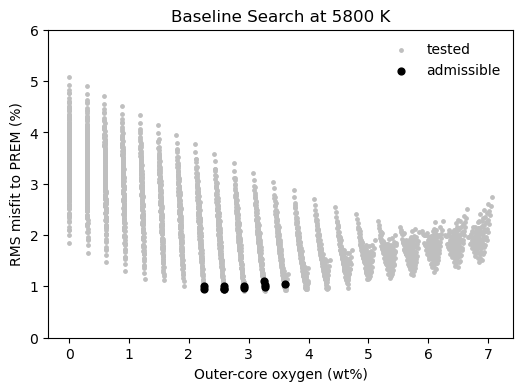

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(wt["O"], sweep.rms_misfit_pct, s=6, color="0.75", label="tested")
ax.scatter(wt.loc[adm.index, "O"], adm.rms_misfit_pct, s=24, color="black", label="admissible")
ax.set_xlabel("Outer-core oxygen (wt%)")
ax.set_ylabel("RMS misfit to PREM (%)")
ax.set_ylim(0, 6)
ax.set_title("Baseline Search at 5800 K")
ax.legend(frameon=False)
plt.show()

## 5. Sensitivity scenarios and Monte Carlo (stored results)

These come from `production/` as written by `full_space_rerun.py --production`. Each sensitivity
scenario reruns the search above with one input changed. The Monte Carlo draws the oxygen,
sulfur, silicon and nickel partition coefficients, the ICB temperature and the liquid-iron anchor
400 times and repeats the search for each draw; the carbon coefficient stays at its production
value. Oxygen counts as required when no admissible liquid has 3 mol% oxygen or less.

In [8]:
sens = pd.read_csv("production/sensitivity_summary.csv")
sens[["scenario", "n_admissible", "oxygen_required", "adm_o_min", "adm_o_max"]].rename(columns={
    "n_admissible": "admissible", "oxygen_required": "oxygen required",
    "adm_o_min": "min O (mol frac)", "adm_o_max": "max O (mol frac)"}).set_index("scenario")

,admissible,oxygen required,min O (mol frac),max O (mol frac)
scenario,,,,
T_ICB_5500K,4,True,0.07,0.08
baseline_5800K,11,True,0.07,0.11
T_ICB_6200K,35,True,0.07,0.13
T_ICB_6000K,19,True,0.07,0.11
T_ICB_5700K,11,True,0.07,0.11
D_Si_0.67,4,True,0.07,0.08
D_Si_1.00,35,True,0.07,0.13
B1_oxide,11,True,0.07,0.11


In [9]:
uq = pd.read_csv("production/uq_draws.csv")
ok = uq[uq.admissible == True]
best_wt = pd.DataFrame([F._wt_pct(r.best_o, r.best_si, r.best_s, r.best_c) for r in ok.itertuples()])
print(f"{len(ok)} of {len(uq)} draws admissible; oxygen required in {int(ok.oxygen_required.sum())} of {len(ok)}")
summary = best_wt.quantile([0.16, 0.5, 0.84]).add_suffix(" (wt%)")
summary["ICB jump (%)"] = np.percentile(ok.best_jump, [16, 50, 84])
summary.index = ["16th percentile", "median", "84th percentile"]
summary.round(2)

198 of 400 draws admissible; oxygen required in 179 of 198


,O (wt%),Si (wt%),S (wt%),C (wt%),ICB jump (%)
16th percentile,2.59,0.58,0.66,0.96,5.75
median,3.61,1.16,1.33,0.98,6.47
84th percentile,4.31,2.26,1.64,0.99,7.15


## Where to go next

- `bash reproduce.sh` reruns everything, including the Monte Carlo and the figures in `figures/`.
- `production_checks.py` and `icb_circularity.py` test the carbon coefficient and the oxygen
  requirement; their outputs are `production/checks.txt` and `production/circularity.txt`.
- `../qha_campaign/` holds the first-principles equation-of-state campaign, and
  `verify_qha_eos.py` compares it with the imported ledger.